### Iteration 51: full-episode imperfect park

**What changed:** Retrain after omitting prepared training rows within ±0.25 s of PARK. This was an unapproved substitution for bursty packet loss. Preserve it as exploratory evidence only; it does not complete the requested packet-loss experiment.

**Type:** Outside agreed scope. Seed 7 only; 100 validation and 100 test targets, with both learned networks controlling the complete episode. No conventional arm holding controller or extra gravity compensation is active.

**Result:** test PARK 97/100, STOP 97/100, full success 0/100; validation full success 0/100. Median parking error is 8.99 cm among 97 parked attempts. Median STOP distance is 945.0 mm among 97 stopped attempts. 3 attempts did not PARK; 0 parked without STOP. Neither is silently discarded from success.

**Comparison with iteration 49 (random_start_retrained):** PARK count changes by +12; STOP by +12; successes by +0. On the same 82 targets parked by both, the median paired change in parking error is -17.03 cm. On the same 82 targets stopped by both, the median paired change at STOP is +153.8 mm. Negative changes mean smaller errors. These paired subsets exclude failures, so read them alongside the counts, not as overall success rates.

**Training provenance:** selected epochs: driving 299, torque 1194, STOP 599. The curves below belong to the actual checkpoint; frozen stress tests reuse their parent training histories and do not represent new training. Driving predicts four wheel speeds and time to PARK (trigger 0.25 s). The arm predicts seven torques; its STOP network predicts distance (trigger 10 mm). Command losses are MSE, with separate auxiliary MSE terms; run weights are equal. Saved configuration and histories give scaling and exact coefficients.

**Limits:** these test targets have been viewed in earlier experiments. This is a reused-test comparison, not an untouched final estimate. One seed cannot establish seed robustness. Success requires PARK, STOP and distance at STOP ≤10 mm. Closest approach and later drift are diagnostics, not substitutes for that criterion. The complete per-target table, pre-PARK arm analysis, all loss terms, STOP/drift plots and 100-replay player follow below.

**Scope correction:** bursty packets remain untested. Do not describe this row deletion as packet loss or mark that roadmap task complete.


In [198]:
from pathlib import Path
import sys,json,uuid
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,HTML
sys.path.insert(0,str(Path('../arm').resolve()))
import report_curriculum as overnight
def lazy_player(url,height=850):
    k=uuid.uuid4().hex[:8]
    return HTML(f"<div><button onclick=\"var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'\" style=\"padding:8px 14px\">Load the 3D player</button><iframe id=\"player{k}\" style=\"display:none;width:100%;height:{height}px;border:0\"></iframe></div>")

full_name='imperfect_park'
display(overnight.build(full_name).round(3))
print('Validation and test are distinct. No fitting occurs in these analysis cells.')

,seed,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
split,,,,,,,,,,,,,,,,,,
val,7,100,99,98,0,0.0,0.0,3.699,8.561,5.932,884.712,930.705,7.2,7.241,2,0,1663.993,16.243
test,7,100,97,97,0,0.0,0.0,3.699,8.994,6.484,894.544,945.007,6.5,6.504,3,0,1649.266,15.112


Validation and test are distinct. No fitting occurs in these analysis cells.


In [199]:
full_config=json.loads((overnight.ROOT/full_name/'test/config.json').read_text())
display(full_config)
for kind in ('driving','torque','stop'):
    chosen=json.loads((overnight.models(full_name)/f'{kind}_seed7_summary.json').read_text())
    print(kind, 'selected epoch',chosen['selected_epoch'],'validation loss',chosen['selected_val_loss'])

{'cases': [11,
  17,
  33,
  35,
  40,
  43,
  44,
  48,
  52,
  56,
  65,
  83,
  92,
  97,
  98,
  113,
  136,
  147,
  148,
  154,
  162,
  196,
  221,
  229,
  232,
  239,
  248,
  260,
  271,
  274,
  277,
  281,
  285,
  302,
  306,
  311,
  315,
  316,
  317,
  361,
  413,
  427,
  432,
  463,
  478,
  479,
  492,
  502,
  534,
  545,
  554,
  571,
  585,
  586,
  592,
  599,
  600,
  605,
  628,
  632,
  642,
  646,
  652,
  653,
  664,
  669,
  671,
  683,
  693,
  700,
  707,
  708,
  722,
  729,
  730,
  738,
  741,
  750,
  770,
  779,
  806,
  834,
  845,
  846,
  848,
  854,
  857,
  859,
  872,
  883,
  898,
  903,
  905,
  945,
  952,
  958,
  981,
  985,
  986,
  989],
 'split': 'test',
 'seed': 7,
 'jobs': 4,
 'models': '/media/nm/Fast Drive/comp0245-golden11109/overnight_20261105/imperfect_park/models',
 'condition': {'encoder_noise_sd': 0.0001,
  'sensor_seed': 7,
  'damping': 1.0,
  'elasticity': 1.0,
  'inertia': 0.001,
  'delay_ms': 3},
 'model_hashes': {'driving

driving selected epoch 299 validation loss 0.3996012210845947
torque selected epoch 1194 validation loss 0.08523980528116226
stop selected epoch 599 validation loss 0.0031310394406318665


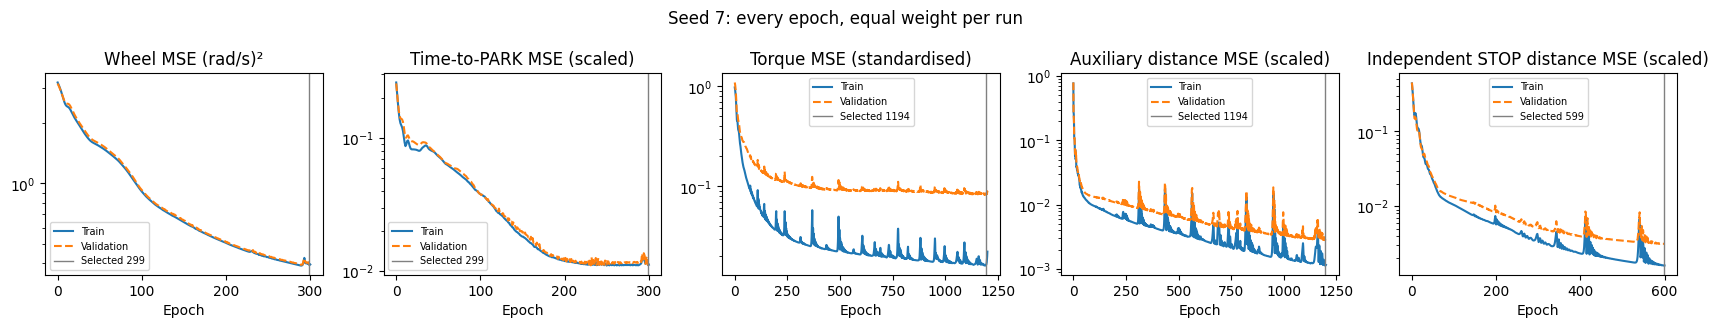

All training and validation epochs. Test scores are not training losses.


In [200]:
overnight.losses(full_name);plt.show()
print('All training and validation epochs. Test scores are not training losses.')

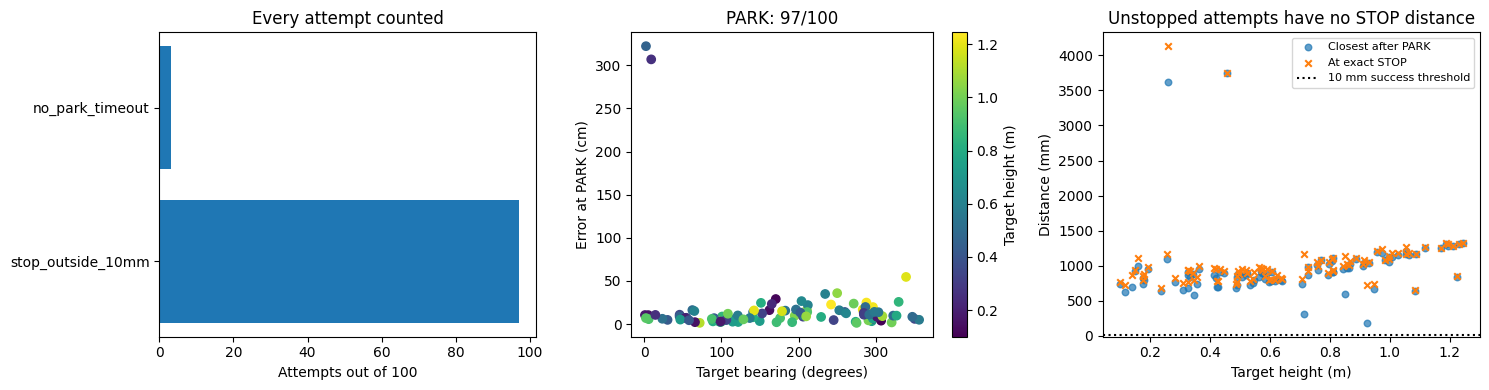

,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,5.467,5.472,10.528,2.848,849.938,816.019,815.905,-34.033,0.136,False,12.728,0.994,0.986,1.042,0.178
17,stop_outside_10mm,False,True,7.200,7.200,9.711,15.068,1186.711,1152.799,1152.727,-33.984,0.266,False,16.505,0.658,194.926,1.095,1.028
33,stop_outside_10mm,False,True,9.400,9.400,14.100,13.650,774.569,701.306,701.138,-73.432,0.091,False,19.826,0.700,259.736,1.504,0.422
35,stop_outside_10mm,False,True,6.233,6.235,5.978,4.267,953.628,887.621,887.492,-66.136,0.091,False,14.808,0.852,111.687,1.257,0.589
40,stop_outside_10mm,False,True,7.233,7.241,8.640,8.671,943.452,869.067,868.856,-74.597,0.152,False,15.795,0.639,205.751,1.041,0.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,stop_outside_10mm,False,True,5.100,5.100,8.498,-4.923,918.728,875.169,875.149,-43.579,0.351,False,12.129,0.982,347.116,1.181,0.493
981,stop_outside_10mm,False,True,6.000,6.005,14.172,0.369,983.498,840.156,840.027,-143.470,0.203,False,14.155,0.995,297.945,1.569,0.564
985,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,2647.354,NaN,NaN,True,22.879,0.933,284.446,1.417,1.210


In [201]:
full_report=overnight.select(full_name)
full_report.outcomes(7);plt.show()
display(full_report.table(7).round(3))

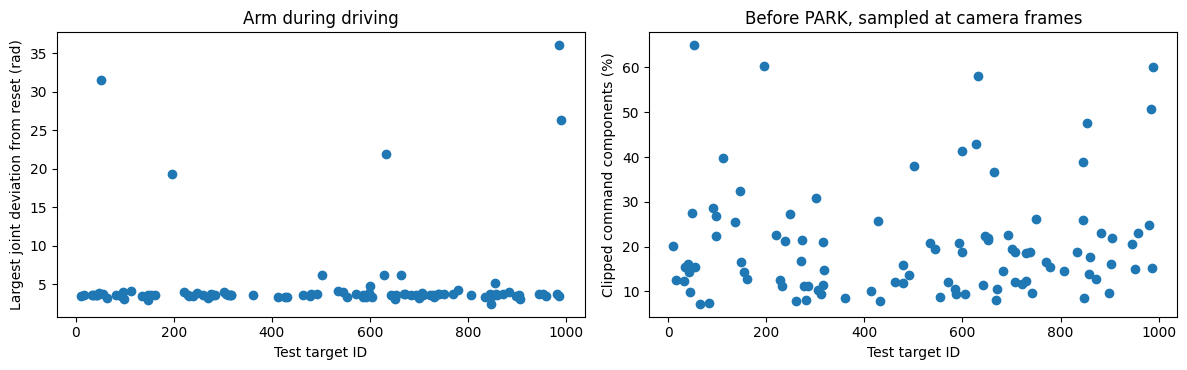

,status,prepark_frames,max_arm_deviation_rad,maximum_command_Nm,torque_clipped_fraction
dot,,,,,
11,stop_outside_10mm,164,3.4714,30.0,0.2012
17,stop_outside_10mm,216,3.6500,30.0,0.1263
33,stop_outside_10mm,282,3.6680,30.0,0.1226
35,stop_outside_10mm,187,3.6342,30.0,0.1543
40,stop_outside_10mm,217,3.6650,30.0,0.1606
...,...,...,...,...,...
958,stop_outside_10mm,153,3.4548,30.0,0.2297
981,stop_outside_10mm,180,3.7874,30.0,0.2476
985,no_park_timeout,387,36.0118,30.0,0.5079


Learned torques are applied from reset. No expert holding or added gravity term.


In [202]:
overnight.holding(full_name);plt.show()
display(overnight.hold_table(full_name).round(4))
print('Learned torques are applied from reset. No expert holding or added gravity term.')

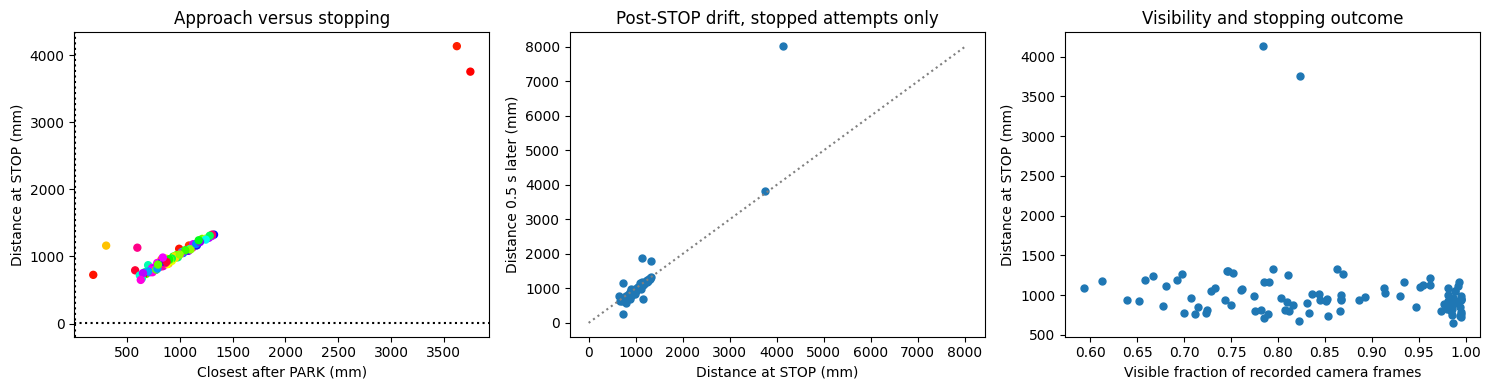

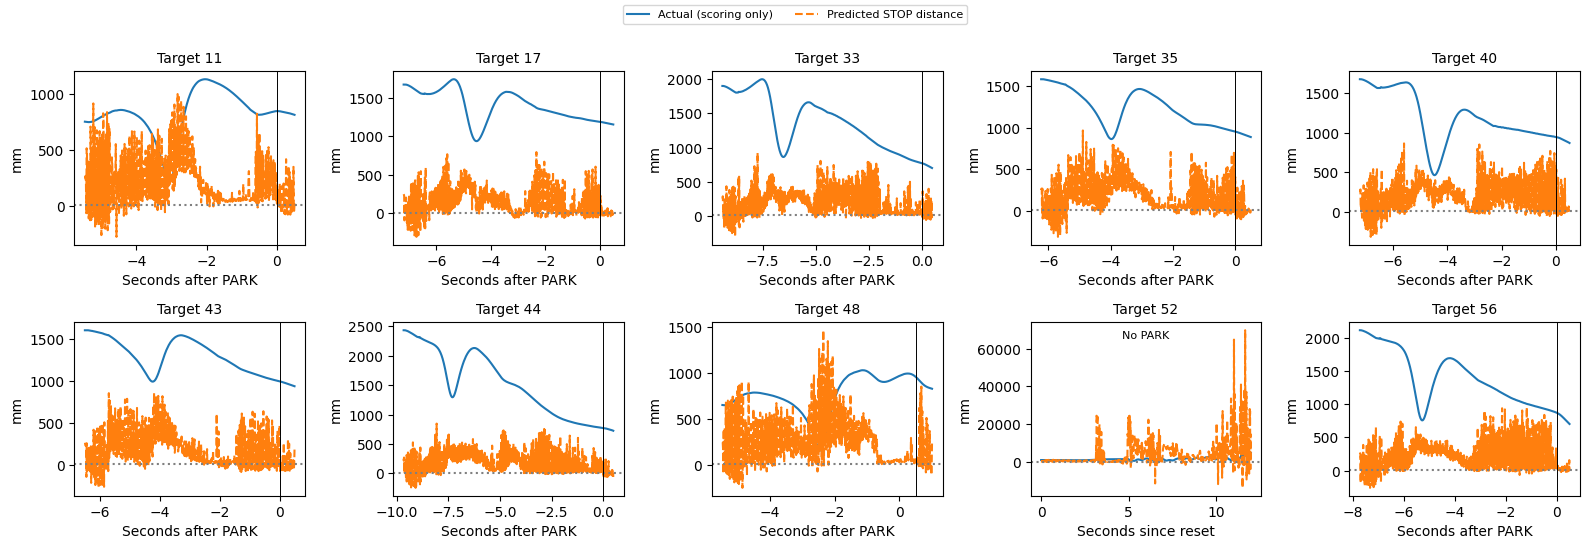

Closest approach, exact STOP, and 0.5-second drift are different measurements.


In [203]:
full_report=overnight.select(full_name)
full_report.stopping(7);plt.show()
full_report.distances(7);plt.show()
print('Closest approach, exact STOP, and 0.5-second drift are different measurements.')

In [204]:
full_url=overnight.player_url(full_name)
display(lazy_player(full_url))
display(HTML(f'<a href="{full_url}" target="_blank">Open all 100 test replays</a>'))
print('Wheel encoder speeds, wheel commands, PARK and STOP values, applied arm torques, camera and ghost.')

Wheel encoder speeds, wheel commands, PARK and STOP values, applied arm torques, camera and ghost.


In [205]:
display(Markdown(overnight.reading(full_name)))

Both networks controlled the complete run, including learned arm torques before PARK. On validation, 99/100 parked and 0/100 met the full task criterion. On the frozen test comparison, 97/100 parked, 97/100 issued STOP, and 0/100 were within 10 mm at STOP. Median parking error among parked attempts was 9.0 cm; median distance at STOP among stopped attempts was 945.0 mm. Median maximum pre-PARK joint deviation was 3.630 rad. The 0.5 s after STOP is observed with learned torques still active, not a frozen simulation. These are previously viewed test targets and one seed; this is a frozen subsequent comparison, not an untouched estimate of generalisation. All timeouts and failures remain in the denominator.